<a href="https://colab.research.google.com/github/IlhamDharm/244107020220-machine-learning/blob/main/TG9_244107020220_ILHAM_DHARMA_ATMAJA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Klasifikasi 2**

**Praktikum 1**



---


Langkah 1 - Import Library

In [15]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns

Langkah 2 - Membuat Data Dummy

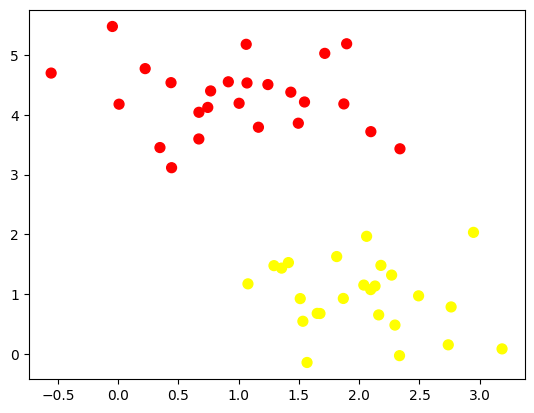

In [16]:
	from sklearn.datasets import make_blobs
	X, y = make_blobs(n_samples=50, centers=2,
	                  random_state=0, cluster_std=0.60)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Buat Ilustrasi Garis Pemisah

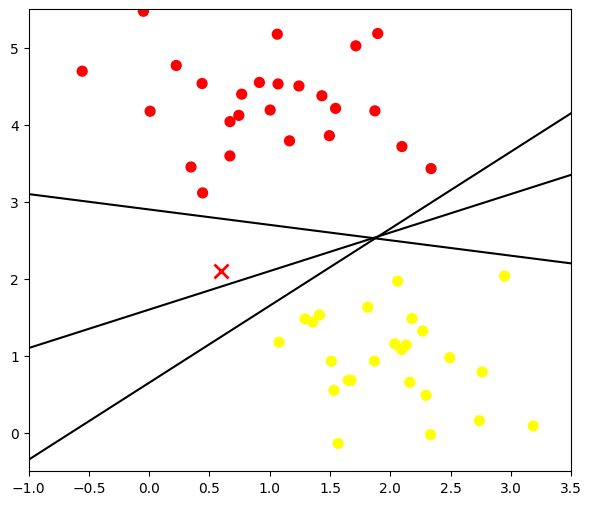

In [17]:
xfit = np.linspace(-1, 3.5)

plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1.0, 3.5)
plt.ylim(-0.5, 5.5)
plt.show()

Langkah 4 - Ilustrasi Margin

(-1.0, 3.5)

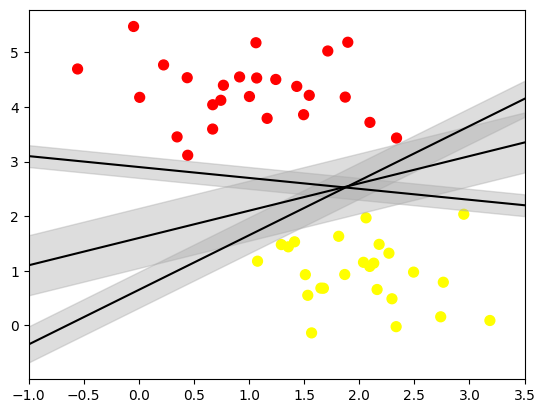

In [18]:
	xfit = np.linspace(-1, 3.5)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

	for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
	    yfit = m * xfit + b
	    plt.plot(xfit, yfit, '-k')
	    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
	                     color='#AAAAAA', alpha=0.4)

	plt.xlim(-1, 3.5)

Langkah 5 - Fitting Model

In [19]:
	from sklearn.svm import SVC # "Support vector classifier"
	model = SVC(kernel='linear', C=1E10)
	model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

fungsi untuk membantu visualisasi hasil fit model

In [20]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

 plotting

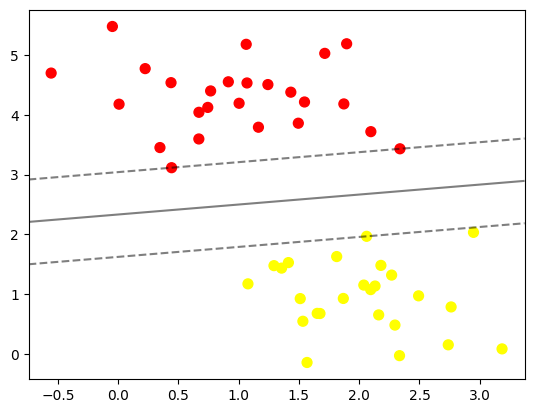

In [21]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(model)

In [22]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

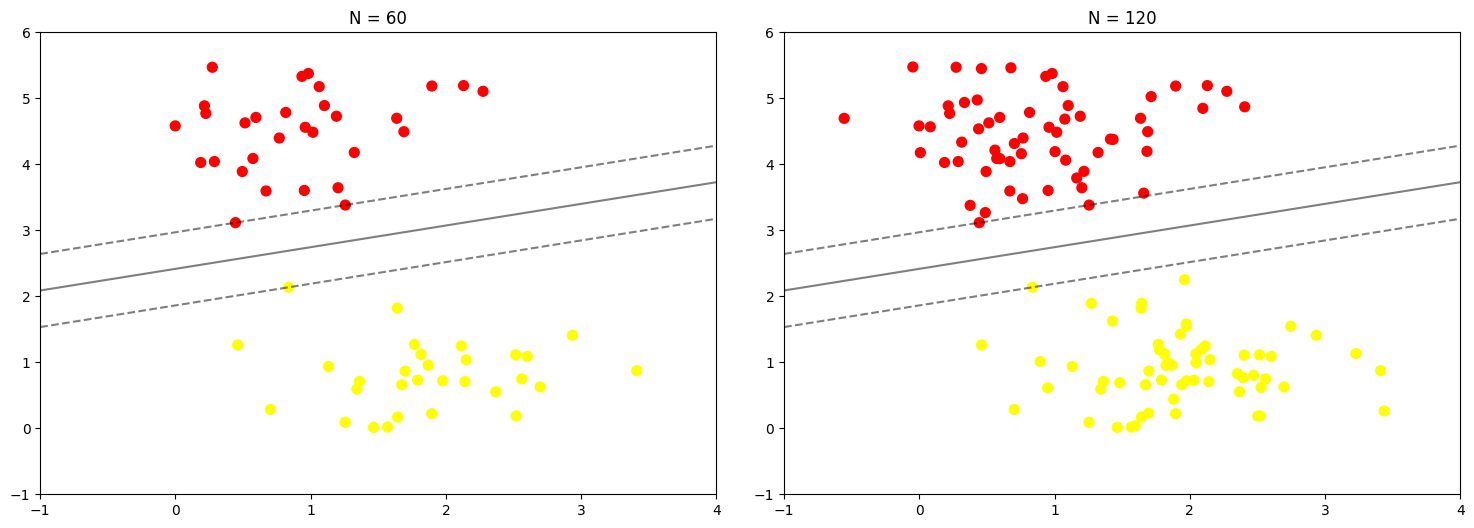

In [23]:
	def plot_svm(N=10, ax=None):
	    X, y = make_blobs(n_samples=200, centers=2,
	                      random_state=0, cluster_std=0.60)
	    X = X[:N]
	    y = y[:N]
	    model = SVC(kernel='linear', C=1E10)
	    model.fit(X, y)

	    ax = ax or plt.gca()
	    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    ax.set_xlim(-1, 4)
	    ax.set_ylim(-1, 6)
	    plot_svc_decision_function(model, ax)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
	for axi, N in zip(ax, [60, 120]):
	    plot_svm(N, axi)
	    axi.set_title('N = {0}'.format(N))

In [24]:
	# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

	from ipywidgets import interact, fixed
	interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>



---

# Praktikum 2 **bold text**

Langkah 1 - Ilustrasi Data Non-Linier

Langkah 1a - Import Library

In [25]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

Langkah 1b - Buat Kembali Fungsi Plotting

In [26]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Langkah 1c - Buat Data Dummy Non-Linier

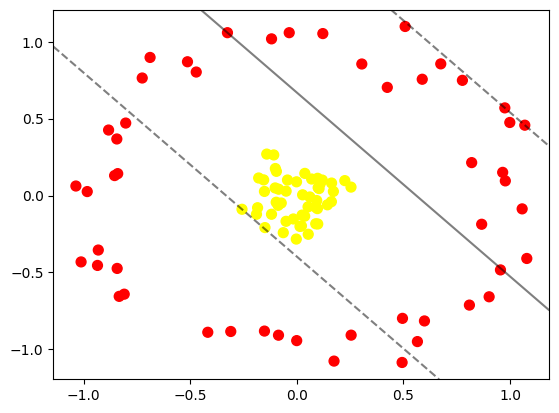

In [29]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

In [32]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

r = np.exp(-(X ** 2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 9.65731192e-01,  1.50846986e-01],
       [-9.30876487e-01, -3.54265995e-01],
       [ 8.67236515e-01, -1.86619393e-01],
       [-8.56563720e-02, -9.08122164e-01],
       [-9.64756349e-02, -4.34914555e-02],
       [ 5.08293516e-01,  1.09954749e+00],
       [-1.51508094e-01, -8.81289193e-01],
       [-1.88922740e-01, -1.21504091e-01],
       [-8.54307876e-01,  1.29982777e-01],
       [-4.34262675e-02,  1.01033968e-01],
       [ 1.43721504e-01, -6.01362073e-02],
       [-8.43910294e-01,  3.68008651e-01],
       [ 5.29663067e-02, -7.33050101e-02],
       [-1.49134067e-01, -2.08251458e-01],
       [ 1.19751676e-01,  1.00751989e-01],
       [ 9.75828988e-01,  5.70163910e-01],
       [-9.34527842e-01, -4.54371298e-01],
       [-1.07935367e-01,  2.64167192e-01],
       [ 9.78923742e-02,  1.12232426e-01],
       [-9.55270328e-02,  1.57528247e-01],
       [-7.27605464e-02, -4.85541814e-02],
       [ 9.78166898e-01,  9.54066545e-02],
       [ 8.20361666e-01,  2.14263939e-01],
       [-1.01370179e-01,  4.96120251e-02],
       [ 9.99188832e-01,  4.75182805e-01],
       [-5.12504438e-01,  8.70130306e-01],
       [ 3.71443849e-02, -1.33894052e-01],
       [ 2.25396252e-01,  9.71729976e-02],
       [-3.09497726e-01, -8.83948541e-01],
       [ 5.98905499e-01, -8.15361507e-01],
       [ 5.38258225e-02, -2.51670162e-01],
       [ 5.65874057e-01, -9.49588930e-01],
       [-1.01155489e+00, -4.31478252e-01],
       [-2.59282401e-04, -9.43276292e-01],
       [-5.02963116e-02, -1.67416276e-01],
       [-8.42296163e-01, -4.73878779e-01],
       [-1.55243130e-01,  1.01956313e-01],
       [-6.87969120e-01,  8.98199671e-01],
       [-8.72705435e-02, -6.35245643e-02],
       [-1.57842930e-02, -1.52198758e-01],
       [ 9.55431255e-01, -4.83479690e-01],
       [-8.09257190e-01, -6.41282108e-01],
       [-7.24816254e-01,  7.64478359e-01],
       [-8.32783951e-01, -6.55530606e-01],
       [ 1.74807344e-01, -1.07651322e+00],
       [ 1.62385713e-01, -3.97686754e-02],
       [ 1.05712611e+00, -8.65645835e-02],
       [ 2.50964794e-02, -1.27060817e-01],
       [ 9.84336314e-02, -1.84810348e-01],
       [-1.08531745e-03,  8.94448911e-02],
       [-1.18486189e-01, -1.21624209e-01],
       [ 8.09725145e-01, -7.12280142e-01],
       [ 4.95847508e-01, -7.98530707e-01],
       [ 2.20270647e-02, -1.97518128e-01],
       [-1.03589076e+00,  6.20549282e-02],
       [-8.50115839e-02,  4.13520629e-02],
       [-1.40795849e-01,  2.69718630e-01],
       [-2.56811015e-01, -8.91904754e-02],
       [ 1.10456607e-01,  7.82751621e-02],
       [ 6.13207503e-02, -9.14869336e-03],
       [-1.51552693e-01,  2.68729636e-02],
       [-8.39806528e-01,  1.42633763e-01],
       [ 9.36086527e-02, -3.24901216e-02],
       [ 1.07891866e+00, -4.09083712e-01],
       [-9.82725201e-01,  2.59361928e-02],
       [ 1.71749013e-01,  2.67957592e-02],
       [ 4.94069214e-01, -1.08546614e+00],
       [-4.17308175e-01, -8.89028759e-01],
       [-6.32380959e-02, -2.41353253e-01],
       [ 6.98800645e-02,  1.07551266e-01],
       [-1.00378914e-01,  1.75845480e-01],
       [ 3.79027052e-02,  1.44232814e-01],
       [ 1.51243699e-02, -2.00626652e-01],
       [ 8.90309147e-02, -1.83471197e-01],
       [ 2.74458833e-02,  4.81995781e-03],
       [ 1.06950775e+00,  4.57605641e-01],
       [ 9.02253353e-01, -6.58306310e-01],
       [ 1.00413598e-01,  5.14231040e-02],
       [-3.25082409e-01,  1.05917670e+00],
       [-2.18692338e-03, -2.83000356e-01],
       [ 2.55027675e-01, -9.07789038e-01],
       [-1.83738959e-01, -7.90861650e-02],
       [ 1.63265527e-01,  8.13444670e-02],
       [-4.71465755e-01,  8.03271734e-01],
       [-1.78634847e-01,  1.14267593e-01],
       [ 4.24552139e-01,  7.03487330e-01],
       [-3.53601742e-02,  1.05912999e+00],
       [ 1.22260732e-01,  1.05335467e+00],
       [ 6.75420335e-01,  8.56339415e-01],
       [ 2.54387010e-01,  5.49874762e-02],
       [-8.82579096e-01,  4.26132968e-01],
       [ 1.04709022e-01,  4.57394990e-02

Langkah 2 - Fitting Model

In [33]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

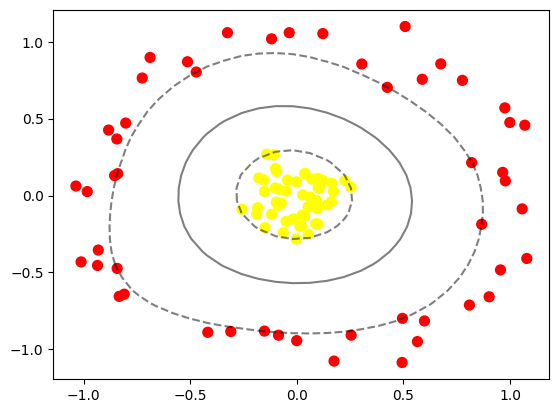

In [34]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')